In [25]:
# Imports
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

In [26]:
# Load the dataset
df = pd.read_csv("/content/train.csv")

# Basic look at the data
print("Shape (rows, columns):", df.shape)
display(df.head())
df.info()

Shape (rows, columns): (45593, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [27]:
# Summary statistics of numeric columns
display(df.describe())

# Missing values (real NaN) per column
print(df.isna().sum())

# Duplicate rows
print("Duplicated rows:", df.duplicated().sum())

# Unique values of text columns (to spot hidden problems like 'NaN ')
for col in df.select_dtypes(include="object").columns:
    print(col, df[col].nunique(), df[col].unique()[:8])

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition
count,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000
mean,17.017729,70.231332,17.465186,70.845702,1.023359
std,8.185109,22.883647,7.335122,21.118812,0.839065
min,-30.905562,-88.366217,0.010000,0.010000,0.000000
25%,12.933284,73.170000,12.988453,73.280000,0.000000
50%,18.546947,75.898497,18.633934,76.002574,1.000000
75%,22.728163,78.044095,22.785049,78.107044,2.000000
max,30.914057,88.433452,31.054057,88.563452,3.000000


ID                             0
Delivery_person_ID             0
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude            0
Restaurant_longitude           0
Delivery_location_latitude     0
Delivery_location_longitude    0
Order_Date                     0
Time_Orderd                    0
Time_Order_picked              0
Weatherconditions              0
Road_traffic_density           0
Vehicle_condition              0
Type_of_order                  0
Type_of_vehicle                0
multiple_deliveries            0
Festival                       0
City                           0
Time_taken(min)                0
dtype: int64
Duplicated rows: 0
ID 45593 ['0x4607 ' '0xb379 ' '0x5d6d ' '0x7a6a ' '0x70a2 ' '0x9bb4 ' '0x95b4 '
 '0x9eb2 ']
Delivery_person_ID 1320 ['INDORES13DEL02 ' 'BANGRES18DEL02 ' 'BANGRES19DEL01 ' 'COIMBRES13DEL02 '
 'CHENRES12DEL01 ' 'HYDRES09DEL03 ' 'RANCHIRES15DEL01 ' 'MYSRES15DEL02 ']
Delivery_person_Age 23 ['37' '34' '23' '38' 

In [28]:
# Work on a copy so the raw data stays untouched
data = df.copy()

# Remove extra spaces from column names and text values
data.columns = data.columns.str.strip()
for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].astype(str).str.strip()

# Turn fake missing values ("NaN") into real NaN
data = data.replace({"NaN": np.nan, "nan": np.nan})

# Clean the target only if it exists in the dataset (i.e. if we are on the train set)
if "Time_taken(min)" in data.columns:
    data["Time_taken(min)"] = (
        data["Time_taken(min)"].astype(str).str.extract(r"(\d+)")[0].astype(float)
    )

# Clean weather: "conditions Sunny" -> "Sunny"
data["Weatherconditions"] = data["Weatherconditions"].str.replace("conditions ", "", regex=False)

# Convert numeric columns that were read as text
for col in ["Delivery_person_Age", "Delivery_person_Ratings", "multiple_deliveries"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Remove duplicate rows
before = len(data)
data = data.drop_duplicates()
print("Duplicates removed:", before - len(data))

# Remove incorrect records
data = data[(data["Delivery_person_Ratings"].isna()) | (data["Delivery_person_Ratings"] <= 5)]
data = data[(data["Delivery_person_Age"].isna()) | (data["Delivery_person_Age"] >= 18)]
for col in ["Restaurant_latitude", "Restaurant_longitude",
            "Delivery_location_latitude", "Delivery_location_longitude"]:
    data = data[data[col].abs() > 1]   # drops zero / bad GPS values

print("Rows after cleaning:", len(data))

Duplicates removed: 0
Rows after cleaning: 41872


In [29]:
# Missing values before handling
print(data.isna().sum()[data.isna().sum() > 0])

# Target-dependent operations (only for training data)
if "Time_taken(min)" in data.columns:
    # Rows without a target value cannot be used for training
    data = data.dropna(subset=["Time_taken(min)"])

# Fill numeric columns with the median
num_cols = data.select_dtypes(include="number").columns
data[num_cols] = data[num_cols].fillna(data[num_cols].median())

# Fill text columns with the most common value
cat_cols = data.select_dtypes(include="object").columns.drop(["ID", "Delivery_person_ID"], errors="ignore")
for col in cat_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

# Handle target outliers only if target column exists
if "Time_taken(min)" in data.columns:
    # Detect outliers in the target with the IQR rule
    q1, q3 = data["Time_taken(min)"].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = ((data["Time_taken(min)"] < low) | (data["Time_taken(min)"] > high)).sum()
    print("Target outliers:", outliers, "| valid range:", low, "to", high)

    # Treat outliers by removing them
    data = data[(data["Time_taken(min)"] >= low) & (data["Time_taken(min)"] <= high)]

data = data.reset_index(drop=True)
print("Final rows:", data.shape[0], "| Missing left:", data.isna().sum().sum())

Delivery_person_Age        1719
Delivery_person_Ratings    1763
Time_Orderd                1519
Road_traffic_density        474
multiple_deliveries         905
Festival                    215
City                       1112
dtype: int64
Target outliers: 247 | valid range: -0.5 to 51.5
Final rows: 41625 | Missing left: 0


,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken(min)
count,41625.000000,41625.000000,41625.000000,41625.000000,41625.000000,41625.000000,41625.000000,41625.000000,41625.000000
mean,29.555940,4.637626,18.523677,76.434467,18.975669,76.984175,1.024577,0.746306,26.157261
std,5.643154,0.307926,6.665230,9.317663,5.468245,3.501286,0.833741,0.559994,9.181691
min,20.000000,2.500000,-30.905562,-88.352885,9.967144,72.778726,0.000000,0.000000,10.000000
25%,25.000000,4.600000,12.980410,73.897902,13.065996,73.939315,0.000000,0.000000,19.000000
50%,30.000000,4.700000,19.003517,76.618203,19.123249,76.662620,1.000000,1.000000,25.000000
75%,34.000000,4.800000,22.750040,78.347554,22.818163,78.405467,2.000000,1.000000,32.000000
max,39.000000,5.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,51.000000


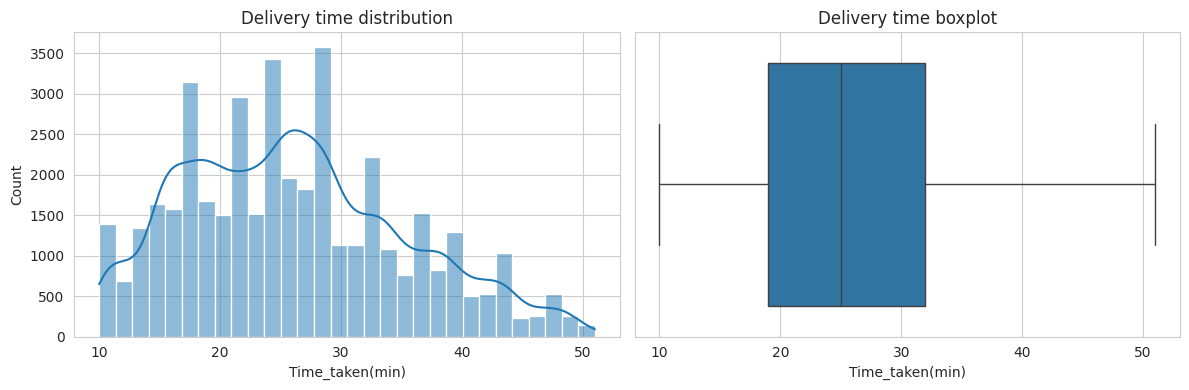

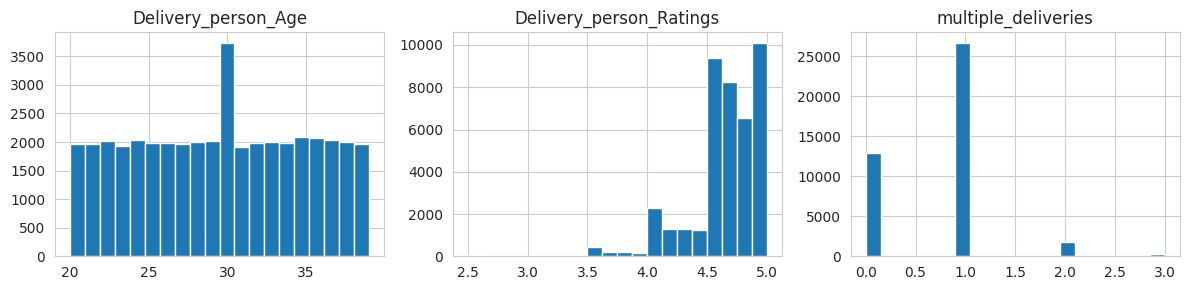

In [30]:
# Summary statistics
display(data.describe())

# Distribution of the target and a boxplot (only if target exists)
if "Time_taken(min)" in data.columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(data["Time_taken(min)"], bins=30, kde=True, ax=axes[0])
    axes[0].set_title("Delivery time distribution")
    sns.boxplot(x=data["Time_taken(min)"], ax=axes[1])
    axes[1].set_title("Delivery time boxplot")
    plt.tight_layout()
    plt.show()
else:
    print("Target 'Time_taken(min)' not present in this dataset (test set). Skipping target distribution plots.")

# Distribution of the numeric features
data[["Delivery_person_Age", "Delivery_person_Ratings", "multiple_deliveries"]].hist(bins=20, figsize=(12, 3), layout=(1, 3))
plt.tight_layout()
plt.show()

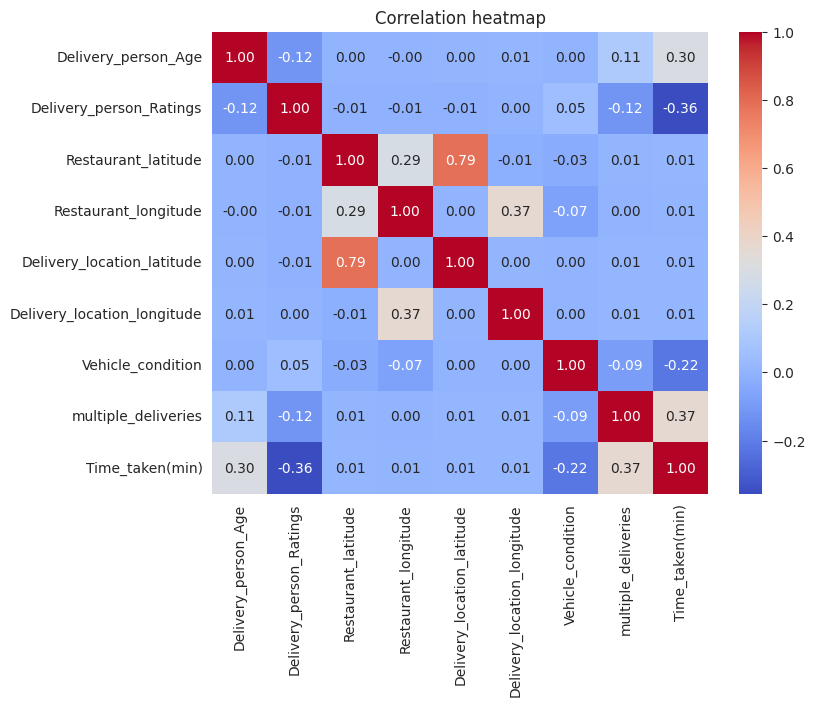

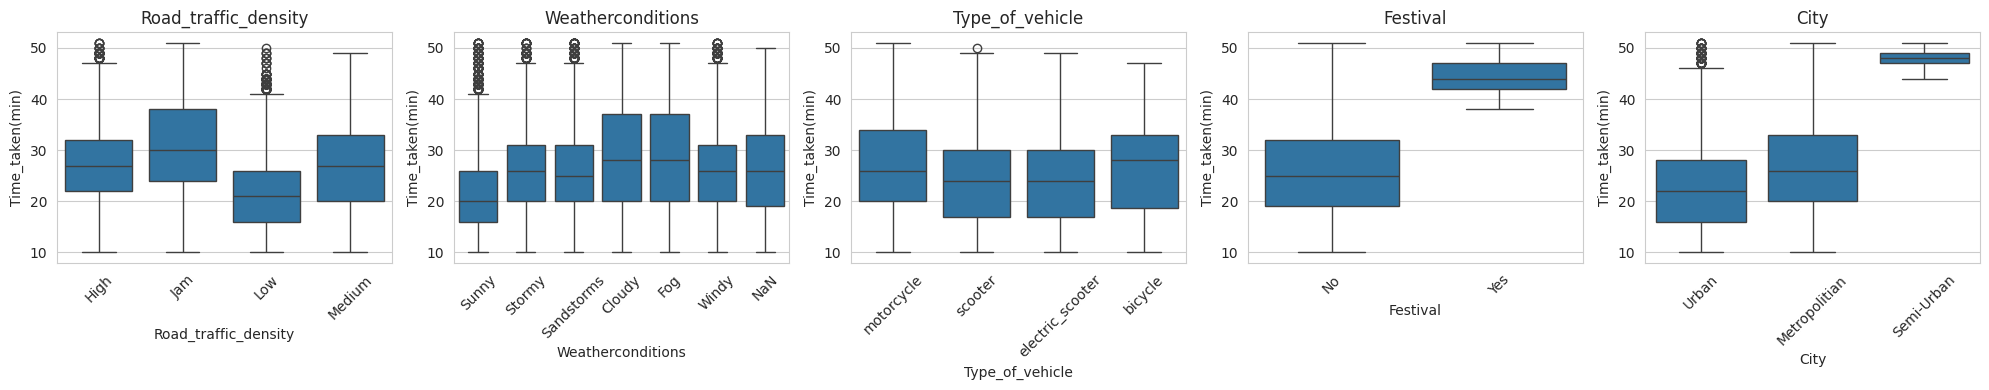

Road_traffic_density
Low       0.352408
Jam       0.308012
Medium    0.242258
High      0.097321
Name: proportion, dtype: float64


In [31]:
# Correlation heatmap of numeric columns
plt.figure(figsize=(8, 6))
sns.heatmap(data.select_dtypes(include="number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

# Average delivery time by category (only if target exists)
cat_features = ["Road_traffic_density", "Weatherconditions", "Type_of_vehicle", "Festival", "City"]
if "Time_taken(min)" in data.columns:
    fig, axes = plt.subplots(1, len(cat_features), figsize=(20, 4))
    for ax, col in zip(axes, cat_features):
        sns.boxplot(data=data, x=col, y="Time_taken(min)", ax=ax)
        ax.set_title(col)
        ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Target 'Time_taken(min)' not present in this dataset (test set). Skipping categorical boxplots.")

# Class distribution of a key category (traffic)
print(data["Road_traffic_density"].value_counts(normalize=True))

In [32]:
# Distance in km between restaurant and customer (Haversine formula)
def haversine(lat1, lon1, lat2, lon2):
    r = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

data["distance_km"] = haversine(
    data["Restaurant_latitude"], data["Restaurant_longitude"],
    data["Delivery_location_latitude"], data["Delivery_location_longitude"],
)

# Time features
order_date = pd.to_datetime(data["Order_Date"], format="%d-%m-%Y", errors="coerce")
ordered = pd.to_datetime(data["Time_Orderd"], format="%H:%M:%S", errors="coerce")
picked = pd.to_datetime(data["Time_Order_picked"], format="%H:%M:%S", errors="coerce")

data["order_hour"] = ordered.dt.hour
data["is_weekend"] = order_date.dt.dayofweek.isin([5, 6]).astype(int)
data["is_rush_hour"] = data["order_hour"].isin([8, 9, 12, 13, 19, 20, 21, 22]).astype(int)

# Time the restaurant took to prepare the order (minutes)
data["prep_time_min"] = (picked - ordered).dt.total_seconds() / 60
data.loc[data["prep_time_min"] < 0, "prep_time_min"] += 24 * 60

# Fill any new missing values
for col in ["order_hour", "prep_time_min"]:
    data[col] = data[col].fillna(data[col].median())

# Remove columns that are not useful for the model
data = data.drop(columns=[
    "ID", "Delivery_person_ID", "Order_Date", "Time_Orderd", "Time_Order_picked",
    "Restaurant_latitude", "Restaurant_longitude",
    "Delivery_location_latitude", "Delivery_location_longitude",
])

print(data.shape)
display(data.head())

(41625, 16)


,Delivery_person_Age,Delivery_person_Ratings,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min),distance_km,order_hour,is_weekend,is_rush_hour,prep_time_min
0,37.0,4.9,Sunny,High,2,Snack,motorcycle,0.0,No,Urban,24.0,3.025149,11,1,0,15.0
1,34.0,4.5,Stormy,Jam,2,Snack,scooter,1.0,No,Metropolitian,33.0,20.183530,19,0,1,5.0
2,23.0,4.4,Sandstorms,Low,0,Drinks,motorcycle,1.0,No,Urban,26.0,1.552758,8,1,1,15.0
3,38.0,4.7,Sunny,Medium,0,Buffet,motorcycle,1.0,No,Metropolitian,21.0,7.790401,18,0,0,10.0
4,32.0,4.6,Cloudy,High,1,Snack,scooter,1.0,No,Metropolitian,30.0,6.210138,13,1,1,15.0


In [33]:
# Split features and target conditionally depending on whether the target column exists
if "Time_taken(min)" in data.columns:
    X = data.drop(columns=["Time_taken(min)"])
    y = data["Time_taken(min)"]
    # Train/test split (80/20), done before scaling to avoid data leakage
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    print("Training target split completed successfully.")
else:
    X = data.copy()
    y = None
    X_train, X_test, y_train, y_test = None, None, None, None
    print("Target 'Time_taken(min)' not found. X contains all features for inference (test set).")

# Separate numeric and categorical columns
num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = X.select_dtypes(include="object").columns.tolist()
print("Numeric:", num_features)
print("Categorical:", cat_features)

# Preprocessing: scale numeric columns, one-hot encode categorical columns
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
])

Training target split completed successfully.
Numeric: ['Delivery_person_Age', 'Delivery_person_Ratings', 'Vehicle_condition', 'multiple_deliveries', 'distance_km', 'order_hour', 'is_weekend', 'is_rush_hour', 'prep_time_min']
Categorical: ['Weatherconditions', 'Road_traffic_density', 'Type_of_order', 'Type_of_vehicle', 'Festival', 'City']


In [34]:
# Check if training data is available (it won't be if we only loaded the test set without targets)
if X_train is not None and y_train is not None:
    # Evaluate a model with regression metrics
    def evaluate(name, model, X_test, y_test):
        pred = model.predict(X_test)
        return {
            "Model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred),
        }

    # Two models: Ridge (simple baseline) and Random Forest (non-linear)
    models = {
        "Ridge": Pipeline([("prep", preprocessor), ("model", Ridge(alpha=1.0))]),
        "Random Forest": Pipeline([("prep", preprocessor),
                                   ("model", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))]),
    }

    results = []
    for name, pipe in models.items():
        pipe.fit(X_train, y_train)
        results.append(evaluate(name, pipe, X_test, y_test))

    results_df = pd.DataFrame(results).sort_values("RMSE")
    display(results_df)
else:
    print("Cannot train or evaluate models because the target variable 'Time_taken(min)' is missing from the dataset (this is a test/inference set).")
    print("To make predictions, you should load your trained model pipeline and call `model.predict(X)`.")

,Model,MAE,RMSE,R2
1,Random Forest,3.155552,3.984285,0.810191
0,Ridge,4.813917,6.080955,0.557860


In [35]:
# Tune the Random Forest with randomized search
param_grid = {
    "model__n_estimators": [100,150],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_split": [ 5, 10],
    "model__min_samples_leaf": [3, 5],
}

search = RandomizedSearchCV(
    models["Random Forest"],
    param_distributions=param_grid,
    n_iter=8,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)

# Compare before and after tuning
best_model = search.best_estimator_
tuned = evaluate("Random Forest (tuned)", best_model, X_test, y_test)
results_df = pd.concat([results_df, pd.DataFrame([tuned])], ignore_index=True)
display(results_df)

Best parameters: {'model__n_estimators': 150, 'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_depth': 15}


,Model,MAE,RMSE,R2
0,Random Forest,3.155552,3.984285,0.810191
1,Ridge,4.813917,6.080955,0.557860
2,Random Forest (tuned),3.114964,3.920396,0.816229


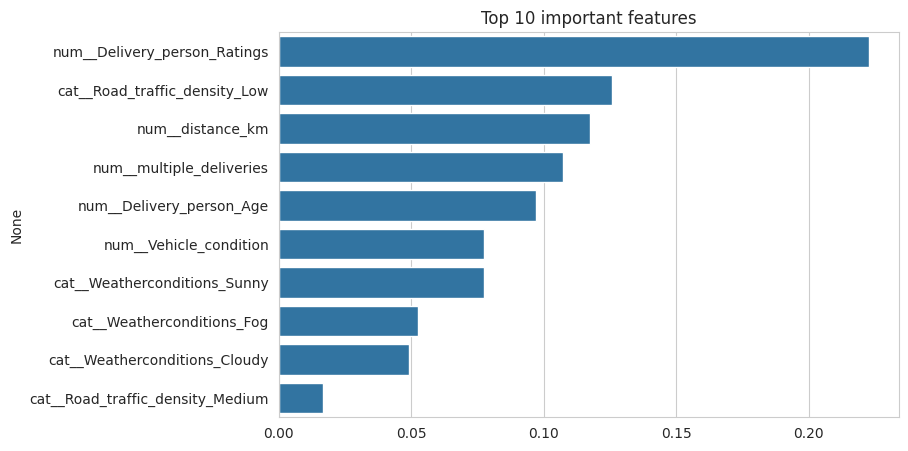

Predicted: 25.1 min | Actual: 23.0 min


In [36]:
# Feature importance of the tuned Random Forest
feature_names = best_model.named_steps["prep"].get_feature_names_out()
importances = best_model.named_steps["model"].feature_importances_
imp = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index)
plt.title("Top 10 important features")
plt.show()

# Save the final model
joblib.dump(best_model, "model.joblib")

# Test a prediction on one row from the test set
loaded = joblib.load("model.joblib")
sample = X_test.iloc[[0]]
print("Predicted:", round(loaded.predict(sample)[0], 1), "min | Actual:", y_test.iloc[0], "min")

In [37]:
import sklearn; print(sklearn.__version__)

1.6.1


In [38]:
import os, joblib

joblib.dump(best_model, "model.joblib", compress=9)
print(round(os.path.getsize("model.joblib") / 1e6, 1), "MB")

11.7 MB


In [39]:
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Third model: Gradient Boosting, same preprocessing pipeline
gb = clone(models["Random Forest"]).set_params(
    model=GradientBoostingRegressor(random_state=42)
)
gb.fit(X_train, y_train)
pred = gb.predict(X_test)

print("MAE :", round(mean_absolute_error(y_test, pred), 2))
print("RMSE:", round(mean_squared_error(y_test, pred) ** 0.5, 2))
print("R2  :", round(r2_score(y_test, pred), 2))

MAE : 3.53
RMSE: 4.44
R2  : 0.76
